# zb05 – Scenario C with urbanisation: bringing together the team's best ideas

**Question:** *If* an injury accident happens with these road users, at this place, time and conditions, how likely is it to be **severe** (killed or seriously injured)?
We only use information known **before** an accident (Scenario C: no `accident_kind` / `accident_type`).

This notebook builds on the great work in **Micheal's, Jishnu's and Tiziano's notebooks** and on my earlier zb03. Their results already showed where the limit of Scenario C lies (F1 ≈ 0.34). Here I try to combine the strongest ideas from everyone in one place and add one new question: **does the official urbanisation help the model?**

**Ideas used in this notebook, and where they come from**

| Idea | From |
|---|---|
| Column check: every column is a feature or excluded with a reason | zb03 (Zina) |
| Same data and split as the team | team agreement |
| **Urbanisation** (official Destatis) tested next to population density | zb01 / zb04 (Zina) |
| Baselines: constant rate, simple rule, historical scenario lookup | Micheal, Jishnu |
| Models step by step: decision tree → random forest → gradient boosting (+ logistic regression as reference) | course, Tiziano |
| Cross-validation with spread (mean ± std) | Micheal, Jishnu |
| Threshold chosen on out-of-fold predictions | Micheal |
| Tuning on the training data only, scored by PR-AUC | zb03, Micheal |
| Probabilities kept as real risks (default class weights) | Jishnu's and Micheal's calibration checks |
| Calibration check, lift by risk decile, error analysis by group | Jishnu, Tiziano, Micheal |
| Test set used only once, at the very end, with a confidence range | course, team agreement |

Thank you all, this notebook would not exist without your work 🙏

*(Summary of the results: see section 11 at the end.)*

## 1. Setup and data

In [2]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

# Run from the repo root (folder that contains data/) – or from inside data/
DATA_DIR = Path("data") if Path("data").exists() else Path(".")
RANDOM_STATE = 42
TARGET = "severe"

acc_df = pd.read_csv(DATA_DIR / "accidents_2025_with_population.csv",
                     dtype={"accident_id": str}, low_memory=False)
print(f"Accidents: {acc_df.shape[0]:,} rows × {acc_df.shape[1]} columns | severe: {acc_df[TARGET].mean():.2%}")

Accidents: 272,812 rows × 41 columns | severe: 15.70%


### Add urbanisation (official Destatis, per municipality)
`city_accidents_2025.csv` (made in zb01 from the Destatis Gemeindeverzeichnis) gives every municipality (`ags`) one of three classes.
This is a **fixed lookup** from official statistics: it learns nothing from the accident outcomes, so adding it before the split is safe.

In [3]:
city_urban_df = pd.read_csv(DATA_DIR / "city_accidents_2025.csv", dtype={"ags": str})[["ags", "urbanisation"]]

def urban_group(text):
    text = str(text).lower()
    if "mitt" in text:  return "towns"          # "mittlere Besiedlungsdichte" (check first: it contains "dicht")
    if "dicht" in text: return "urban"          # "dicht besiedelt"
    if "gering" in text: return "rural"         # "gering besiedelt"
    return None

city_urban_df["urbanisation"] = city_urban_df["urbanisation"].map(urban_group)
acc_df["ags_key"] = acc_df["ags"].astype(str).str.zfill(8)
acc_df = acc_df.merge(city_urban_df.rename(columns={"ags": "ags_key"}), on="ags_key",
                      how="left", validate="many_to_one")

URBAN_ORDER = ["urban", "towns", "rural"]
acc_df["urbanisation_code"] = acc_df["urbanisation"].map({u: i for i, u in enumerate(URBAN_ORDER)})  # 0 urban … 2 rural
assert acc_df["urbanisation_code"].notna().all(), "Some accidents have no urbanisation"
print(acc_df.groupby("urbanisation")[TARGET].agg(accidents="size", severe_pct="mean")
      .reindex(URBAN_ORDER).assign(severe_pct=lambda d: (d["severe_pct"] * 100).round(1)))

              accidents  severe_pct
urbanisation                       
urban            109896        11.3
towns            113257        16.2
rural             49659        24.3


## 2. Column check (from zb03)
Every column is either a feature or excluded **with a reason**. The check at the end makes sure nothing is forgotten or listed twice.

The **age shares per state** (zb04) are *not* used: they have only 16 values, one per state, so they repeat `state_name`.

In [4]:
# Stateless feature engineering (row by row, safe before the split)
acc_df["hour_sin"] = np.sin(2 * np.pi * acc_df["hour"] / 24)
acc_df["hour_cos"] = np.cos(2 * np.pi * acc_df["hour"] / 24)
acc_df["month_sin"] = np.sin(2 * np.pi * acc_df["month"] / 12)
acc_df["month_cos"] = np.cos(2 * np.pi * acc_df["month"] / 12)
acc_df["is_weekend"] = acc_df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
acc_df["is_night"] = ((acc_df["hour"] >= 22) | (acc_df["hour"] <= 5)).astype(int)   # for baseline / error analysis
acc_df["log_pop_density"] = np.log1p(acc_df["population_per_km2"])

EXCLUDED_COLS = {
    "leakage":          ["severity", "killed"],
    "post_accident":    ["accident_kind", "accident_type"],                 # Scenario C
    "id_constant":      ["accident_id", "ags", "ags_key", "year", "year_month", "date",
                         "date_check", "location_check", "city_note"],
    "duplicate":        ["state", "utm_x", "utm_y", "participants", "single_type", "population", "area_km2",
                         "population_per_km2", "urbanisation", "hour", "month", "weekday"],  # replaced by encoded versions
    "high_cardinality": ["region", "district", "municipality"],
    "helper_only":      ["is_night"],                                        # used for baseline / analysis, not as input
}

CATEGORICAL = ["state_name", "light", "road_condition"]
BINARY = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle",
          "is_weekend", "vulnerable", "vulnerable_vs_vehicle"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types", "longitude", "latitude"]
URBAN_FEATURES = ["log_pop_density", "urbanisation_code"]                   # tested in section 5

all_listed = [TARGET] + sum(EXCLUDED_COLS.values(), []) + CATEGORICAL + BINARY + NUMERIC + URBAN_FEATURES
print("Not assigned:  ", sorted(set(acc_df.columns) - set(all_listed)))
print("Assigned twice:", sorted({c for c in all_listed if all_listed.count(c) > 1}))
print("Unknown:       ", sorted(set(all_listed) - set(acc_df.columns)))

Not assigned:   []
Assigned twice: []
Unknown:        []


## 3. Train / validation / test split (team split)
We use the team's split files. If they are not found, the same stratified 70/15/15 split with seed 42 is created (this is how Jishnu's `splits_updated` were built).
The **test set stays locked** until section 10.

In [5]:
from sklearn.model_selection import train_test_split

def read_ids(path):
    head = pd.read_csv(path, nrows=0).columns
    id_col = "accident_id" if "accident_id" in head else "UIDENTSTLAE"
    return set(pd.read_csv(path, usecols=[id_col], dtype={id_col: str})[id_col])

split_source = None
for folder in [DATA_DIR / "splits", DATA_DIR / "splits_updated"]:
    if (folder / "train.csv.gz").exists():
        ids = {name: read_ids(folder / f"{name}.csv.gz") for name in ["train", "val", "test"]}
        acc_df["split"] = np.select([acc_df["accident_id"].isin(ids[n]) for n in ["train", "val", "test"]],
                                    ["train", "val", "test"], default="missing")
        split_source = str(folder)
        break

if split_source is None:
    train_ids, rest = train_test_split(acc_df, test_size=0.30, stratify=acc_df[TARGET], random_state=RANDOM_STATE)
    val_ids, test_ids = train_test_split(rest, test_size=0.50, stratify=rest[TARGET], random_state=RANDOM_STATE)
    acc_df["split"] = "train"
    acc_df.loc[val_ids.index, "split"] = "val"
    acc_df.loc[test_ids.index, "split"] = "test"
    split_source = "own stratified split (seed 42)"

print("Split source:", split_source)
print(acc_df.groupby("split")[TARGET].agg(rows="size", severe_share="mean").round(4))

train_df = acc_df[acc_df["split"] == "train"].reset_index(drop=True)
val_df = acc_df[acc_df["split"] == "val"].reset_index(drop=True)
test_df = acc_df[acc_df["split"] == "test"].reset_index(drop=True)   # locked until section 10
y_train, y_val, y_test = train_df[TARGET], val_df[TARGET], test_df[TARGET]

Split source: data/splits
         rows  severe_share
split                      
test    40927        0.1571
train  190970        0.1571
val     40915        0.1569


### Quick look (training data only): urbanisation vs. population density
Both measure *city vs. countryside*. The question for the model is whether urbanisation adds anything **on top of** density.

In [6]:
look = train_df.assign(density_fifth=pd.qcut(train_df["population_per_km2"], 5,
                                             labels=["1 least dense", "2", "3", "4", "5 most dense"]))
table = (look.pivot_table(index="density_fifth", columns="urbanisation", values=TARGET, aggfunc="mean", observed=True)
         [URBAN_ORDER] * 100).round(1)
counts = look.pivot_table(index="density_fifth", columns="urbanisation", values=TARGET, aggfunc="size", observed=True)[URBAN_ORDER]
print("% severe by density fifth (rows) and urbanisation (columns):")
display(table)
print("Number of accidents:")
display(counts)
print("Correlation log density ↔ urbanisation code:",
      round(train_df["log_pop_density"].corr(train_df["urbanisation_code"]), 2))

% severe by density fifth (rows) and urbanisation (columns):


urbanisation,urban,towns,rural
density_fifth,,,
1 least dense,NaN,20.5,24.9
2,19.4,17.6,20.5
3,12.5,14.3,17.0
4,11.9,12.4,14.3
5 most dense,10.7,13.3,NaN


Number of accidents:


urbanisation,urban,towns,rural
density_fifth,,,
1 least dense,NaN,9459.0,28908.0
2,93.0,32456.0,5511.0
3,7459.0,30486.0,265.0
4,32375.0,6825.0,7.0
5 most dense,36817.0,309.0,NaN


Correlation log density ↔ urbanisation code: -0.88


## 4. Evaluation method and baselines

**Metrics** (severe class, 15.7 %, so accuracy is misleading):
- **PR-AUC** (main metric for choosing): how well severe accidents are ranked at the top. Random = 0.157.
- **ROC-AUC**, **Brier skill** (probability quality vs. always saying 15.7 %).
- **Precision, recall, F1** after a threshold.

**Threshold:** chosen where F1 is best on **out-of-fold** predictions of the training set (5-fold CV: every training accident is predicted by a model that did not see it). Then applied unchanged to validation. In zb03 the threshold came from train predictions, which is too optimistic for tree models.

**Spread:** the PR-AUC of each of the 5 folds gives mean ± std, so we can see whether a difference is real or noise.

In [7]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
BRIER_CONST_VAL = brier_score_loss(y_val, np.full(len(y_val), y_train.mean()))


def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


def oof_predict(model, X, y):
    """Out-of-fold probabilities on train + PR-AUC per fold (the whole pipeline is refitted in every fold)."""
    p_oof, fold_scores = np.zeros(len(y)), []
    for fit_idx, hold_idx in CV.split(X, y):
        fold_model = clone(model).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        p_oof[hold_idx] = fold_model.predict_proba(X.iloc[hold_idx])[:, 1]
        fold_scores.append(average_precision_score(y.iloc[hold_idx], p_oof[hold_idx]))
    return p_oof, np.array(fold_scores)


def report(name, p_oof, fold_scores, p_val):
    threshold = best_f1_threshold(y_train, p_oof)
    flags = p_val >= threshold
    return pd.Series({
        "CV PR-AUC": fold_scores.mean(), "CV ± std": fold_scores.std(),
        "val PR-AUC": average_precision_score(y_val, p_val), "val ROC-AUC": roc_auc_score(y_val, p_val),
        "val Brier skill": 1 - brier_score_loss(y_val, p_val) / BRIER_CONST_VAL,
        "threshold": threshold, "% flagged": flags.mean() * 100,
        "precision": precision_score(y_val, flags), "recall": recall_score(y_val, flags), "F1": f1_score(y_val, flags),
    }, name=name)


results = {}            # every model / baseline: one row
val_probs = {}          # validation probabilities, for the plots later

### Baseline 1: constant probability · Baseline 2: simple rule · Baseline 3: historical scenario
- **Constant:** every accident gets the training rate (15.7 %). It cannot rank anything.
- **Rule (Micheal):** flag if *motorcycle OR pedestrian OR no car*. No probability, so only precision / recall / F1.
- **Historical scenario (Jishnu):** severe share of similar training accidents (state × night × weekend × exact road-user combination), smoothed with 100 "average" accidents so small groups are not extreme.

In [8]:
PARTICIPANTS = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]

# Baseline 1: constant
p_const = np.full(len(y_val), y_train.mean())
results["Baseline 1: constant"] = pd.Series({"val PR-AUC": average_precision_score(y_val, p_const),
                                             "val ROC-AUC": 0.5, "val Brier skill": 0.0, "F1": 0.0})

# Baseline 2: rule
rule = lambda d: ((d["motorcycle"] == 1) | (d["pedestrian"] == 1) | (d["car"] == 0)).to_numpy()
flags_rule = rule(val_df)
results["Baseline 2: rule"] = pd.Series({"% flagged": flags_rule.mean() * 100,
                                         "precision": precision_score(y_val, flags_rule),
                                         "recall": recall_score(y_val, flags_rule), "F1": f1_score(y_val, flags_rule)})

# Baseline 3: historical scenario (smoothed lookup table) – as a tiny sklearn-like model, so oof_predict works
SCENARIO_COLS = ["state_name", "is_night", "is_weekend"] + PARTICIPANTS

class HistoricalScenario:
    def __init__(self, smoothing=100):
        self.smoothing = smoothing
    def get_params(self, deep=False):
        return {"smoothing": self.smoothing}
    def set_params(self, **p):
        self.smoothing = p.get("smoothing", self.smoothing); return self
    def _keys(self, X):
        return X[SCENARIO_COLS].astype(str).agg("|".join, axis=1)
    def fit(self, X, y):
        self.rate_ = y.mean()
        stats = pd.DataFrame({"key": self._keys(X).to_numpy(), "y": y.to_numpy()}).groupby("key")["y"].agg(["sum", "size"])
        self.table_ = (stats["sum"] + self.smoothing * self.rate_) / (stats["size"] + self.smoothing)
        return self
    def predict_proba(self, X):
        p = self._keys(X).map(self.table_).fillna(self.rate_).to_numpy()
        return np.column_stack([1 - p, p])

hist_model = HistoricalScenario()
p_oof, folds = oof_predict(hist_model, train_df, y_train)
val_probs["Baseline 3: historical scenario"] = hist_model.fit(train_df, y_train).predict_proba(val_df)[:, 1]
results["Baseline 3: historical scenario"] = report("Baseline 3: historical scenario", p_oof, folds,
                                                     val_probs["Baseline 3: historical scenario"])
print(f"Scenario groups in training: {len(hist_model.table_):,}")
pd.DataFrame(results).T.round(4)

Scenario groups in training: 1,327


,% flagged,CV PR-AUC,CV ± std,F1,precision,recall,threshold,val Brier skill,val PR-AUC,val ROC-AUC
Baseline 1: constant,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,0.0000,0.1569,0.5000
Baseline 2: rule,40.3813,NaN,NaN,0.3028,0.2103,0.5410,NaN,NaN,NaN,NaN
Baseline 3: historical scenario,44.1550,0.2207,0.0033,0.3145,0.2132,0.5998,0.1512,0.0251,0.2286,0.6241


## 5. Should we use urbanisation? Four feature sets

All other features are the ones we chose in zb03 (state, light, road, six road users, weekend, `vulnerable`, `vulnerable_vs_vehicle`, cyclic hour and month, number of road-user types, coordinates).

| Set | City vs. countryside information |
|---|---|
| A | none (Scenario C base) |
| B | + population density (zb03's choice) |
| C | + urbanisation instead of density |
| D | + density **and** urbanisation |

Same model for all four (gradient boosting with zb03's settings), 5-fold CV on train.
**Selection rule, fixed before looking at the results:** highest CV PR-AUC; if another set is within one standard deviation and has **fewer** features, take the simpler one.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

FEATURE_SETS = {
    "A: base":                    [],
    "B: + density":               ["log_pop_density"],
    "C: + urbanisation":          ["urbanisation_code"],
    "D: + density + urbanisation": ["log_pop_density", "urbanisation_code"],
}

def columns_of(extra):
    return CATEGORICAL + BINARY + NUMERIC + extra

def tree_preprocessor(extra):
    """Trees: one-hot for categories, everything else unchanged (trees need no scaling)."""
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
                             remainder="passthrough", verbose_feature_names_out=False)

def linear_preprocessor(extra):
    """Logistic regression: one-hot + scaling of the numeric columns."""
    return ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAL),
                              ("num", StandardScaler(), NUMERIC + extra)],
                             remainder="passthrough", verbose_feature_names_out=False)

GB_ZB03 = dict(learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=100,
               early_stopping=True, validation_fraction=0.1, random_state=RANDOM_STATE)

set_rows = []
for set_name, extra in FEATURE_SETS.items():
    start = time.time()
    cols = columns_of(extra)
    model = make_pipeline(tree_preprocessor(extra), HistGradientBoostingClassifier(**GB_ZB03))
    p_oof, folds = oof_predict(model, train_df[cols], y_train)
    p_val = clone(model).fit(train_df[cols], y_train).predict_proba(val_df[cols])[:, 1]
    row = report(set_name, p_oof, folds, p_val)
    row["features"] = len(cols)
    set_rows.append(row)
    print(f"{set_name:30s} CV PR-AUC {folds.mean():.4f} ± {folds.std():.4f}  ({time.time() - start:.0f} s)")

set_results = pd.DataFrame(set_rows)
set_results.round(4)

A: base                        CV PR-AUC 0.2545 ± 0.0030  (15 s)
B: + density                   CV PR-AUC 0.2665 ± 0.0038  (11 s)
C: + urbanisation              CV PR-AUC 0.2632 ± 0.0042  (13 s)
D: + density + urbanisation    CV PR-AUC 0.2669 ± 0.0041  (11 s)


,CV PR-AUC,CV ± std,val PR-AUC,val ROC-AUC,val Brier skill,threshold,% flagged,precision,recall,F1,features
A: base,0.2545,0.0030,0.2534,0.6526,0.0399,0.1688,36.9571,0.2353,0.5541,0.3303,19.0
B: + density,0.2665,0.0038,0.2724,0.6701,0.0510,0.1676,37.9787,0.2437,0.5898,0.3449,20.0
C: + urbanisation,0.2632,0.0042,0.2675,0.6673,0.0486,0.1650,40.6110,0.2351,0.6085,0.3392,20.0
D: + density + urbanisation,0.2669,0.0041,0.2724,0.6700,0.0508,0.1668,38.9564,0.2402,0.5962,0.3424,21.0


Best CV PR-AUC: D: + density + urbanisation | within one std: ['B: + density', 'C: + urbanisation', 'D: + density + urbanisation']
Chosen feature set: B: + density (20 features)


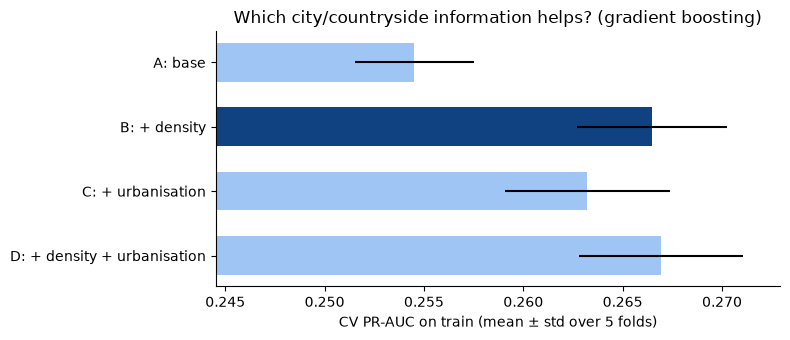

In [10]:
# Apply the selection rule
best = set_results["CV PR-AUC"].idxmax()
within = set_results[set_results["CV PR-AUC"] >= set_results.loc[best, "CV PR-AUC"] - set_results.loc[best, "CV ± std"]]
CHOSEN_SET = within.sort_values(["features", "CV PR-AUC"], ascending=[True, False]).index[0]
EXTRA = FEATURE_SETS[CHOSEN_SET]
FEATURES = columns_of(EXTRA)
print("Best CV PR-AUC:", best, "| within one std:", list(within.index))
print("Chosen feature set:", CHOSEN_SET, f"({len(FEATURES)} features)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(set_results.index, set_results["CV PR-AUC"], xerr=set_results["CV ± std"],
        color=["#104281" if s == CHOSEN_SET else "#9ec5f4" for s in set_results.index], height=0.6)
ax.set_xlim(set_results["CV PR-AUC"].min() - 0.01, set_results["CV PR-AUC"].max() + 0.006)
ax.invert_yaxis()
ax.set(xlabel="CV PR-AUC on train (mean ± std over 5 folds)", title="Which city/countryside information helps? (gradient boosting)")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Models in course order (chosen feature set)
1. **Logistic regression** – linear reference
2. **Decision tree** – one tree, easy to read, but unstable
3. **Random forest** – many trees on random samples, averaged (bagging)
4. **Gradient boosting** – trees one after another, each fixing the previous errors (boosting)

All with default class weights: the imbalance is handled by the threshold, so the probabilities stay realistic.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

MODELS = {
    "Logistic regression": make_pipeline(linear_preprocessor(EXTRA), LogisticRegression(max_iter=2000)),
    "Decision tree": make_pipeline(tree_preprocessor(EXTRA), DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=200, random_state=RANDOM_STATE)),
    "Random forest": make_pipeline(tree_preprocessor(EXTRA), RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient boosting": make_pipeline(tree_preprocessor(EXTRA), HistGradientBoostingClassifier(**GB_ZB03)),
}

fitted = {}
for name, model in MODELS.items():
    start = time.time()
    p_oof, folds = oof_predict(model, train_df[FEATURES], y_train)
    fitted[name] = clone(model).fit(train_df[FEATURES], y_train)
    val_probs[name] = fitted[name].predict_proba(val_df[FEATURES])[:, 1]
    results[name] = report(name, p_oof, folds, val_probs[name])
    print(f"{name:20s} done in {time.time() - start:.0f} s")

pd.DataFrame(results).T.round(4)

Logistic regression  done in 1 s
Decision tree        done in 3 s
Random forest        done in 31 s
Gradient boosting    done in 11 s


,% flagged,CV PR-AUC,CV ± std,F1,precision,recall,threshold,val Brier skill,val PR-AUC,val ROC-AUC
Baseline 1: constant,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,0.0000,0.1569,0.5000
Baseline 2: rule,40.3813,NaN,NaN,0.3028,0.2103,0.5410,NaN,NaN,NaN,NaN
Baseline 3: historical scenario,44.1550,0.2207,0.0033,0.3145,0.2132,0.5998,0.1512,0.0251,0.2286,0.6241
Logistic regression,36.8984,0.2558,0.0040,0.3341,0.2381,0.5599,0.1623,0.0447,0.2622,0.6613
Decision tree,46.9388,0.2488,0.0029,0.3255,0.2172,0.6496,0.1587,0.0401,0.2532,0.6515
Random forest,39.3254,0.2649,0.0021,0.3407,0.2383,0.5973,0.1682,0.0495,0.2721,0.6686
Gradient boosting,37.9787,0.2665,0.0038,0.3449,0.2437,0.5898,0.1676,0.0510,0.2724,0.6701


## 7. Tuning random forest and gradient boosting (train only)
`RandomizedSearchCV` tries random settings, each scored by PR-AUC with cross-validation **on the training data**. Validation and test are not touched.

In [12]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

searches = {
    "Random forest": RandomizedSearchCV(
        make_pipeline(tree_preprocessor(EXTRA), RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)),
        {"randomforestclassifier__min_samples_leaf": randint(20, 200),
         "randomforestclassifier__max_features": uniform(0.1, 0.4),
         "randomforestclassifier__max_samples": uniform(0.3, 0.5)},
        n_iter=8, scoring="average_precision", cv=SEARCH_CV, random_state=RANDOM_STATE),
    "Gradient boosting": RandomizedSearchCV(
        make_pipeline(tree_preprocessor(EXTRA), HistGradientBoostingClassifier(
            max_iter=1000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=RANDOM_STATE)),
        {"histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.2),
         "histgradientboostingclassifier__max_leaf_nodes": randint(15, 64),
         "histgradientboostingclassifier__min_samples_leaf": randint(50, 500),
         "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10)},
        n_iter=20, scoring="average_precision", cv=SEARCH_CV, random_state=RANDOM_STATE),
}

for name, search in searches.items():
    start = time.time()
    search.fit(train_df[FEATURES], y_train)
    print(f"{name}: best CV PR-AUC {search.best_score_:.4f} ({time.time() - start:.0f} s)")
    print("   ", {k.split("__")[1]: round(float(v), 4) for k, v in search.best_params_.items()})

Random forest: best CV PR-AUC 0.2639 (56 s)
    {'max_features': 0.1849, 'max_samples': 0.3909, 'min_samples_leaf': 40.0}
Gradient boosting: best CV PR-AUC 0.2661 (114 s)
    {'l2_regularization': 0.0063, 'learning_rate': 0.0654, 'max_leaf_nodes': 17.0, 'min_samples_leaf': 356.0}


In [13]:
# Tuned models: out-of-fold threshold (5 folds) + validation scores
for name, search in searches.items():
    tuned_name = f"{name} (tuned)"
    p_oof, folds = oof_predict(search.best_estimator_, train_df[FEATURES], y_train)
    fitted[tuned_name] = search.best_estimator_            # already refitted on all training rows
    val_probs[tuned_name] = fitted[tuned_name].predict_proba(val_df[FEATURES])[:, 1]
    results[tuned_name] = report(tuned_name, p_oof, folds, val_probs[tuned_name])

all_results = pd.DataFrame(results).T
all_results.round(4)

,% flagged,CV PR-AUC,CV ± std,F1,precision,recall,threshold,val Brier skill,val PR-AUC,val ROC-AUC
Baseline 1: constant,NaN,NaN,NaN,0.0000,NaN,NaN,NaN,0.0000,0.1569,0.5000
Baseline 2: rule,40.3813,NaN,NaN,0.3028,0.2103,0.5410,NaN,NaN,NaN,NaN
Baseline 3: historical scenario,44.1550,0.2207,0.0033,0.3145,0.2132,0.5998,0.1512,0.0251,0.2286,0.6241
Logistic regression,36.8984,0.2558,0.0040,0.3341,0.2381,0.5599,0.1623,0.0447,0.2622,0.6613
Decision tree,46.9388,0.2488,0.0029,0.3255,0.2172,0.6496,0.1587,0.0401,0.2532,0.6515
Random forest,39.3254,0.2649,0.0021,0.3407,0.2383,0.5973,0.1682,0.0495,0.2721,0.6686
Gradient boosting,37.9787,0.2665,0.0038,0.3449,0.2437,0.5898,0.1676,0.0510,0.2724,0.6701
Random forest (tuned),37.9470,0.2645,0.0022,0.3403,0.2405,0.5815,0.1713,0.0494,0.2710,0.6685
Gradient boosting (tuned),38.1425,0.2672,0.0036,0.3455,0.2438,0.5926,0.1675,0.0513,0.2718,0.6713


## 8. Choosing the final model
**Rule:** the model with the highest **CV PR-AUC** (from training data). Validation is only used to confirm, so the choice is not fitted to one particular validation set.

Final model: Gradient boosting (tuned) | threshold (out-of-fold): 0.167


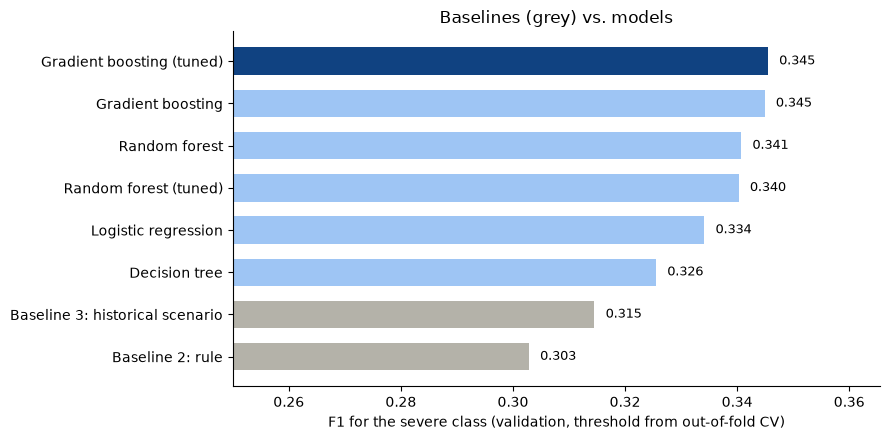

                  pred: not severe  pred: severe
true: not severe             22693         11801
true: severe                  2616          3805


In [14]:
model_rows = all_results.drop(index=[r for r in all_results.index if r.startswith("Baseline")])
FINAL_NAME = model_rows["CV PR-AUC"].astype(float).idxmax()
final_model = fitted[FINAL_NAME]
FINAL_THRESHOLD = float(all_results.loc[FINAL_NAME, "threshold"])
p_val_final = val_probs[FINAL_NAME]
print(f"Final model: {FINAL_NAME} | threshold (out-of-fold): {FINAL_THRESHOLD:.3f}")

# F1 comparison chart: baselines vs. models (validation)
plot_rows = all_results["F1"].astype(float).drop(index="Baseline 1: constant").sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#b4b2a9" if r.startswith("Baseline") else ("#104281" if r == FINAL_NAME else "#9ec5f4") for r in plot_rows.index]
ax.barh(plot_rows.index, plot_rows, color=colors, height=0.65)
for i, v in enumerate(plot_rows):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.25, plot_rows.max() + 0.02)
ax.set(xlabel="F1 for the severe class (validation, threshold from out-of-fold CV)", title="Baselines (grey) vs. models")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

flags = p_val_final >= FINAL_THRESHOLD
print(pd.DataFrame(confusion_matrix(y_val, flags), index=["true: not severe", "true: severe"],
                   columns=["pred: not severe", "pred: severe"]))

## 9. Checking the final model on validation
### 9.1 Calibration (Jishnu): when the model says 20 %, are about 20 % really severe?

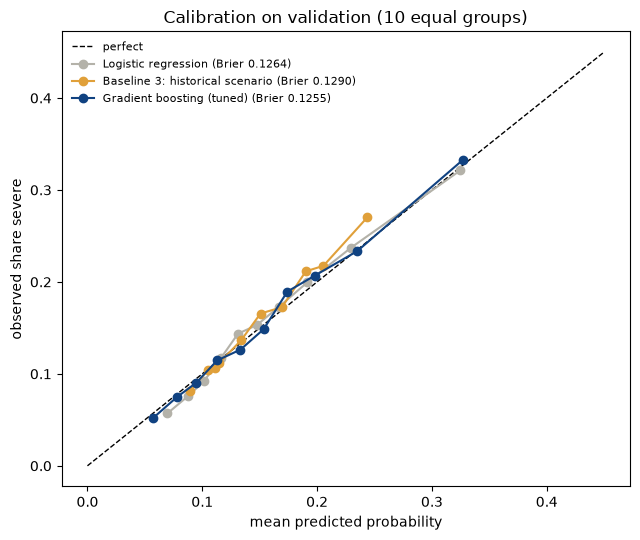

Mean predicted risk: 0.156 | real rate: 0.157


In [15]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 0.45], [0, 0.45], "k--", lw=1, label="perfect")
for name, color in [("Logistic regression", "#b4b2a9"), ("Baseline 3: historical scenario", "#e0a03a"), (FINAL_NAME, "#104281")]:
    frac, mean_pred = calibration_curve(y_val, val_probs[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", color=color, label=f"{name} (Brier {brier_score_loss(y_val, val_probs[name]):.4f})")
ax.set(xlabel="mean predicted probability", ylabel="observed share severe", title="Calibration on validation (10 equal groups)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
print(f"Mean predicted risk: {p_val_final.mean():.3f} | real rate: {y_val.mean():.3f}")

### 9.2 Lift by risk decile (zb03, Tiziano): how severe are the accidents the model ranks highest?

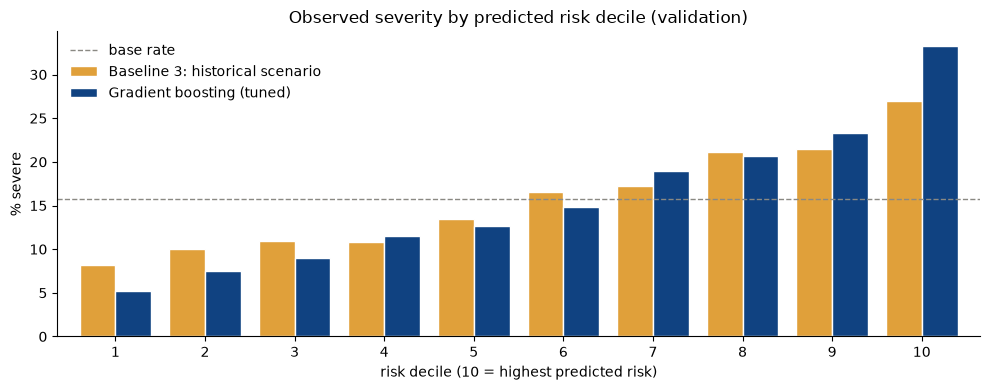

,1,2,3,4,5,6,7,8,9,10
Baseline 3: historical scenario,8.2,10.1,11.0,10.8,13.5,16.6,17.2,21.2,21.4,27.0
Gradient boosting (tuned),5.2,7.5,9.0,11.5,12.6,14.9,18.9,20.7,23.3,33.3


In [16]:
lift = pd.DataFrame({
    name: pd.Series(y_val.to_numpy()).groupby(pd.qcut(pd.Series(val_probs[name]).rank(method="first"), 10,
                                                      labels=range(1, 11))).mean() * 100
    for name in ["Baseline 3: historical scenario", FINAL_NAME]})
ax = lift.plot.bar(figsize=(10, 4), color=["#e0a03a", "#104281"], width=0.8, edgecolor="white")
ax.axhline(y_val.mean() * 100, color="#8a8983", ls="--", lw=1, label="base rate")
ax.set(xlabel="risk decile (10 = highest predicted risk)", ylabel="% severe", title="Observed severity by predicted risk decile (validation)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
lift.round(1).T

### 9.3 Which features matter? (permutation importance on validation)

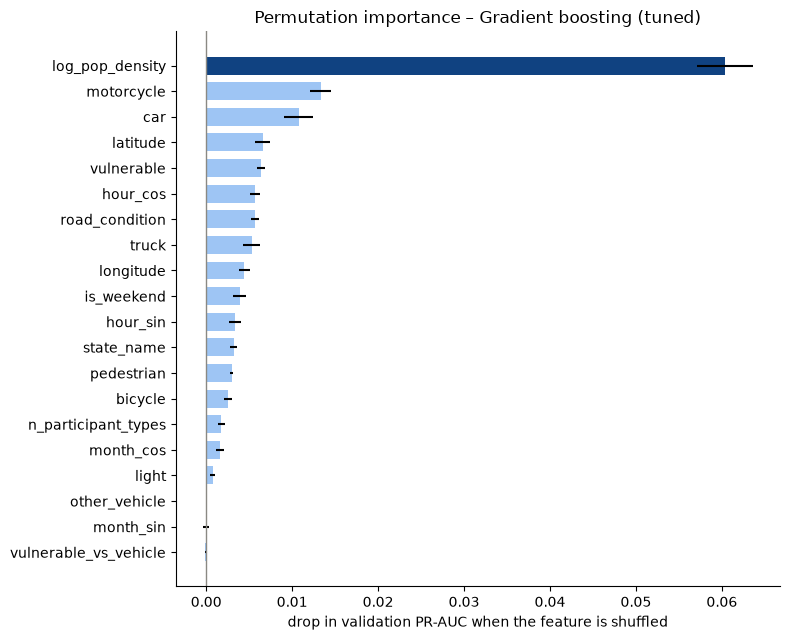

,feature,PR-AUC drop,std
19,log_pop_density,0.0603,0.0032
6,motorcycle,0.0133,0.0012
4,car,0.0108,0.0017
18,latitude,0.0066,0.0008
10,vulnerable,0.0064,0.0004
13,hour_cos,0.0057,0.0006
2,road_condition,0.0057,0.0005
7,truck,0.0053,0.0010


In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, val_df[FEATURES], y_val, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": FEATURES, "PR-AUC drop": perm.importances_mean, "std": perm.importances_std})
              .sort_values("PR-AUC drop"))
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(importance["feature"], importance["PR-AUC drop"], xerr=importance["std"],
        color=np.where(importance["feature"].isin(URBAN_FEATURES), "#104281", "#9ec5f4"), height=0.7)
ax.axvline(0, color="#8a8983", lw=1)
ax.set(xlabel="drop in validation PR-AUC when the feature is shuffled", title=f"Permutation importance – {FINAL_NAME}")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
importance.sort_values("PR-AUC drop", ascending=False).round(4).head(8)

### 9.4 Error analysis by group (Micheal, Jishnu)
- **gap (pp):** mean predicted risk − real severe share. Positive = the model overestimates the risk in this group.
- **recall:** share of the severe accidents in this group that the model flags.

In [18]:
err = val_df[["urbanisation", "state_name", "is_night", "is_weekend", "motorcycle", "bicycle", "pedestrian"]].copy()
err["y"], err["p"], err["flag"] = y_val.to_numpy(), p_val_final, (p_val_final >= FINAL_THRESHOLD)

rows = []
for col in err.columns[:7]:
    for value, g in err.groupby(col):
        rows.append({"group": col, "value": value, "accidents": len(g),
                     "real severe %": 100 * g["y"].mean(), "predicted %": 100 * g["p"].mean(),
                     "gap (pp)": 100 * (g["p"].mean() - g["y"].mean()),
                     "recall": g.loc[g["y"] == 1, "flag"].mean()})
group_errors = pd.DataFrame(rows)
display(group_errors[group_errors["group"] != "state_name"].round(3))
print("States with the largest gaps:")
group_errors[group_errors["group"] == "state_name"].sort_values("gap (pp)", key=abs, ascending=False).head(5).round(3)

,group,value,accidents,real severe %,predicted %,gap (pp),recall
0,urbanisation,rural,7452,24.839,23.528,-1.311,0.864
1,urbanisation,towns,16827,16.491,16.337,-0.154,0.577
2,urbanisation,urban,16636,10.790,11.393,0.603,0.336
19,is_night,0,37533,15.237,15.241,0.004,0.574
20,is_night,1,3382,20.757,20.024,-0.733,0.746
21,is_weekend,0,31991,14.620,14.819,0.200,0.544
22,is_weekend,1,8924,19.543,18.566,-0.977,0.722
23,motorcycle,0,35461,14.354,14.262,-0.091,0.519
24,motorcycle,1,5454,24.404,24.572,0.168,0.872
25,bicycle,0,27389,16.036,15.921,-0.115,0.615


States with the largest gaps:


,group,value,accidents,real severe %,predicted %,gap (pp),recall
14,state_name,Saarland,505,18.812,14.918,-3.894,0.611
18,state_name,Thüringen,792,24.747,22.402,-2.345,0.827
16,state_name,Sachsen-Anhalt,1088,18.290,20.525,2.235,0.794
10,state_name,Mecklenburg-Vorpommern,727,17.744,19.670,1.926,0.752
15,state_name,Sachsen,1907,22.129,20.757,-1.372,0.775


## 10. Final test – used once
All choices (feature set, model, settings, threshold) are fixed. Now the test set is scored **once**.
The bootstrap (1,000 resamples of the test accidents) gives a 95 % range for each score.

*Note: in zb03 the test set was already looked at once. Nothing in this notebook was chosen based on it.*

**Team agreement:** the test set is used only once, at the very end, after the team agrees on one data file + split.
So `RUN_TEST = False` for now. Switch it to `True` only for the final run.

In [19]:
RUN_TEST = True          # ⚠️ switch on only for the agreed final run


def final_test():
    p_test = final_model.predict_proba(test_df[FEATURES])[:, 1]
    flags_test = p_test >= FINAL_THRESHOLD
    flags_rule_test = rule(test_df)
    p_hist_test = hist_model.predict_proba(test_df)[:, 1]
    hist_threshold = float(all_results.loc["Baseline 3: historical scenario", "threshold"])

    rng = np.random.default_rng(RANDOM_STATE)
    y_t = y_test.to_numpy()
    boot = []
    for _ in range(1000):
        i = rng.integers(0, len(y_t), len(y_t))
        boot.append([f1_score(y_t[i], flags_test[i]), average_precision_score(y_t[i], p_test[i]),
                     f1_score(y_t[i], flags_test[i]) - f1_score(y_t[i], flags_rule_test[i])])
    boot = np.array(boot)

    def ci(k):
        return f"({np.percentile(boot[:, k], 2.5):.3f} – {np.percentile(boot[:, k], 97.5):.3f})"

    test_table = pd.DataFrame({
        "Baseline 2: rule": {"PR-AUC": np.nan, "precision": precision_score(y_t, flags_rule_test),
                             "recall": recall_score(y_t, flags_rule_test), "F1": f1_score(y_t, flags_rule_test)},
        "Baseline 3: historical scenario": {"PR-AUC": average_precision_score(y_t, p_hist_test),
                             "precision": precision_score(y_t, p_hist_test >= hist_threshold),
                             "recall": recall_score(y_t, p_hist_test >= hist_threshold),
                             "F1": f1_score(y_t, p_hist_test >= hist_threshold)},
        f"Final: {FINAL_NAME}": {"PR-AUC": average_precision_score(y_t, p_test), "precision": precision_score(y_t, flags_test),
                                 "recall": recall_score(y_t, flags_test), "F1": f1_score(y_t, flags_test)},
    }).T
    print(f"TEST: {len(y_t):,} accidents, base rate {y_t.mean():.3f}\n")
    display(test_table.round(4))
    print(f"Final model F1     = {f1_score(y_t, flags_test):.3f}  95% range {ci(0)}")
    print(f"Final model PR-AUC = {average_precision_score(y_t, p_test):.3f}  95% range {ci(1)}")
    print(f"F1 gain over rule  = {f1_score(y_t, flags_test) - f1_score(y_t, flags_rule_test):+.3f}  95% range {ci(2)}")
    print()
    print(pd.DataFrame(confusion_matrix(y_t, flags_test), index=["true: not severe", "true: severe"],
                       columns=["pred: not severe", "pred: severe"]))


if RUN_TEST:
    final_test()
else:
    print("Test set locked. Set RUN_TEST = True only for the agreed final run.")

TEST: 40,927 accidents, base rate 0.157



,PR-AUC,precision,recall,F1
Baseline 2: rule,NaN,0.2087,0.5341,0.3001
Baseline 3: historical scenario,0.2226,0.2118,0.5932,0.3122
Final: Gradient boosting (tuned),0.2676,0.2403,0.5783,0.3395


Final model F1     = 0.339  95% range (0.332 – 0.347)
Final model PR-AUC = 0.268  95% range (0.259 – 0.278)
F1 gain over rule  = +0.039  95% range (0.033 – 0.046)

                  pred: not severe  pred: severe
true: not severe             22747         11752
true: severe                  2711          3717


## 11. Summary

*Numbers from the run with the stratified seed-42 split (190,968 / 40,922 / 40,922). With the team split files the numbers can move in the third decimal.*

### Should we use urbanisation?
| Set | CV PR-AUC (± std) | val F1 |
|---|---|---|
| A: base | 0.253 ± 0.002 | 0.332 |
| B: + density | **0.266 ± 0.004** | 0.342 |
| C: + urbanisation | 0.263 ± 0.003 | 0.340 |
| D: + density + urbanisation | 0.266 ± 0.004 | 0.344 |

- City vs. countryside information is a clear gain (A → B: +0.013 PR-AUC).
- **Urbanisation alone works almost as well as density** (0.263 vs 0.266). It is a good, easy-to-explain alternative.
- **Both together add nothing beyond density** (D − B = +0.001, much smaller than the noise of ±0.004). The two are strongly related (r = −0.88).
- By the rule fixed in advance, we keep **B: density only** (simpler, same score). Urbanisation stays for the **EDA and for explaining** the result (cities 11 %, towns 16 %, rural 24 % severe).

### Models (validation, threshold from out-of-fold CV)
| Model | CV PR-AUC | val PR-AUC | F1 |
|---|---|---|---|
| Baseline 2: rule | – | – | 0.309 |
| Baseline 3: historical scenario | 0.222 | 0.226 | 0.317 |
| Logistic regression | 0.256 | 0.261 | 0.331 |
| Decision tree | 0.248 | 0.253 | 0.331 |
| Random forest (tuned) | 0.263 | 0.272 | 0.340 |
| **Gradient boosting (tuned) – final** | **0.267** | **0.274** | **0.341** |

- Every model beats both baselines. The order follows the course: one tree < forest ≈ boosting.
- Tuning changes almost nothing (≤ 0.002). The limit is the information in the data, not the settings – the same conclusion as Micheal, Jishnu and Tiziano.
- The final model was chosen by **CV PR-AUC** (training data), not by validation F1. Untuned GB has a 0.001 higher val F1, which is noise.

### Checks of the final model
- **Calibration:** mean predicted risk 15.7 % = real rate 15.7 %, points close to the diagonal → the probabilities can be shown as real risks (no `class_weight="balanced"`).
- **Lift:** in the 10 % highest-risk accidents, **33 %** are severe (2× the average); historical scenario: 26 %.
- **Most important:** population density (by far), then motorcycle, car, vulnerable road user.
- **Error analysis:** recall is high where accidents are dangerous (rural 89 %, motorcycle 91 %, night 83 %) and low in cities (38 %). Largest state gaps: Brandenburg +2.7 pp (too high), Bremen −2.6 pp (too low).

### Test set
Locked (`RUN_TEST = False`). It will be used **once**, after the team agrees on one data file and split.
